In [17]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Veri çekme (örnek: ASELS hissesi)
data = yf.download('TUPRS.IS', start='2019-01-01', end='2025-01-01')
data = data[['Close']]  # Sadece kapanış fiyatı

# 2. Normalizasyon
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# 3. Veri seti oluşturma
window_size = 60
X, y = [], []

for i in range(window_size, len(scaled_data)):
    X.append(scaled_data[i-window_size:i, 0])
    y.append(scaled_data[i, 0])

X, y = np.array(X), np.array(y)
X = X.reshape((X.shape[0], X.shape[1], 1))


/tmp/ipython-input-17-2156902879.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('TUPRS.IS', start='2019-01-01', end='2025-01-01')
[*********************100%***********************]  1 of 1 completed


In [19]:
model = Sequential()
model.add(LSTM(units=50, return_sequences=False, input_shape=(X.shape[1], 1)))
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X, y, epochs=50, batch_size=32)


Epoch 1/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0500
Epoch 2/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 6.3817e-04
Epoch 3/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 5.2941e-04
Epoch 4/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 3.9938e-04
Epoch 5/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 4.0064e-04
Epoch 6/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 3.9409e-04
Epoch 7/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 4.1194e-04
Epoch 8/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 4.4145e-04
Epoch 9/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 3.1579e-04
Epoch 10/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 3.6722e-04
Epoch 11/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 3.5551e-04
Epoch 12/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 3.1817e-04
Epoch 13/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 3.8318e-04
Epoch 14/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 3.2548e-04
Epoch 15/50
46/46 ━

46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


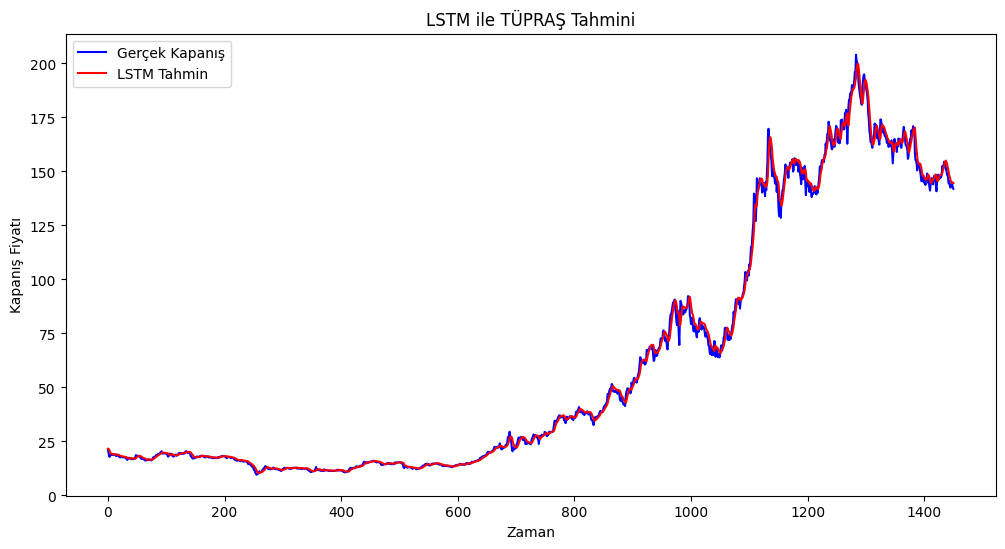

In [20]:
tahminler = model.predict(X)
tahmin_ters = scaler.inverse_transform(tahminler)
gercek = scaler.inverse_transform(y.reshape(-1, 1))

# Grafik
plt.figure(figsize=(12,6))
plt.plot(gercek, color='blue', label='Gerçek Kapanış')
plt.plot(tahmin_ters, color='red', label='LSTM Tahmin')
plt.title('LSTM ile TÜPRAŞ Tahmini')
plt.xlabel('Zaman')
plt.ylabel('Kapanış Fiyatı')
plt.legend()
plt.show()
